# LungLensAI

In [20]:
!pip install kaggle
!pip install -U kagglehub
!pip install seaborn
!pip install pandas
!pip install numpy
!pip install scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 KB 1.2 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 KB 4.4 MB/s eta 0:00:00a 0:00:01


In [23]:
import os
import subprocess
from pathlib import Path
# from google.colab import files
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import metrics as sklearn_metrics
from sklearn.utils import compute_class_weight
import tensorflow as tf
from tensorflow.keras import Sequential, Model,layers,losses,optimizers,metrics as keras_metrics
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


In [ ]:
PROJECT_DIR=Path("/content/LungsLensAi")
SCRIPT_DIR= PROJECT_DIR / "scripts"
KAGGLE_DATASET="paultimothymooney/chest-xray-pneumonia"

DATASET_ROOT= PROJECT_DIR / "data"
TRAIN_DIR = DATASET_ROOT / "chest_xray"  / "train"
VAL_DIR = DATASET_ROOT / "chest_xray" / "val"
TEST_DIR = DATASET_ROOT / "chest_xray" / "test"

SEED = 42
IMG_SIZE = (180, 180)
IMG_SIZE_MOBINET = (224, 180)
BATCH_SIZE = 32
EPOCHS = 10
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

OUTPUT_DIR = PROJECT_DIR / "output"
FINAL_MODEL_PATH = OUTPUT_DIR / "model_final.keras"
CHECKPOINT_PATH= OUTPUT_DIR / "best_model.keras"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg"
}

In [24]:
def download_dataset(dataset_path, kaggle_dataset):
    if os.path.exists(dataset_path) and os.listdir(dataset_path):
        print("Dataset already exists. Skipping download.")
    else:
        print("Downloading dataset from Kaggle...")
        os.makedirs(dataset_path, exist_ok=True)

        download_path = kagglehub.dataset_download(
            kaggle_dataset,
            output_dir=dataset_path
        )

def count_images(folder):
    return sum(
        1 for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    

def showConfusionMatrix(model, test_dataset):
    y_true = np.concatenate(
        [y.numpy() if hasattr(y, "numpy") else y
         for x, y in test_dataset],
        axis=0
    ).reshape(-1)

    y_pred_probs = model.predict(test_dataset, verbose=0).reshape(-1)

    y_pred = (y_pred_probs >= 0.5).astype(int)
    sklearn_metrics.ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=[0, 1],
        display_labels=CLASS_NAMES,
        normalize=None,
        cmap="Blues",
        values_format="d"
    )
    plt.show()
def compare_histories(histories, model_names):
    metrics = ["loss", "accuracy", "auc", "precision"]
    
    fig, axes = plt.subplots(
        len(metrics), 1,
        figsize=(10, 16)
    )

    colors = ["royalblue", "darkorange", "seagreen"]

    for metric, ax in zip(metrics, axes):
        for history, name, color in zip(histories, model_names, colors):
            if metric in history.history:
                ax.plot(
                    history.history[metric],
                    color=color,
                    linestyle="-",
                    linewidth=2,
                    label=f"{name} Train"
                )

            val_metric = f"val_{metric}"
            if val_metric in history.history:
                ax.plot(
                    history.history[val_metric],
                    color=color,
                    linestyle="--",
                    linewidth=2,
                    label=f"{name} Validation"
                )

        ax.set_title(f"{metric.replace('_', ' ').title()} Comparison", fontsize=12, fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.title())
        ax.legend(fontsize=9, loc="upper right")
        ax.grid(True, linestyle=":", alpha=0.5)

    plt.suptitle(
        "Training and Validation Metrics Comparison",
        fontsize=15,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

## 1. Dataset Loading

In [25]:
os.environ["KAGGLE_API_TOKEN"] = "KGAT_0638852ab21c227bddbee980c017f9d1"
download_dataset(DATASET_ROOT,KAGGLE_DATASET)

100%|██████████| 2.29G/2.29G [01:19<00:00, 31.1MB/s]

Extracting files...


## 2. Dataset Exploration

### 2.1 Classes distribution

,Split,Classe,Nombre
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,val,NORMAL,8
3,val,PNEUMONIA,8
4,test,NORMAL,234
5,test,PNEUMONIA,390


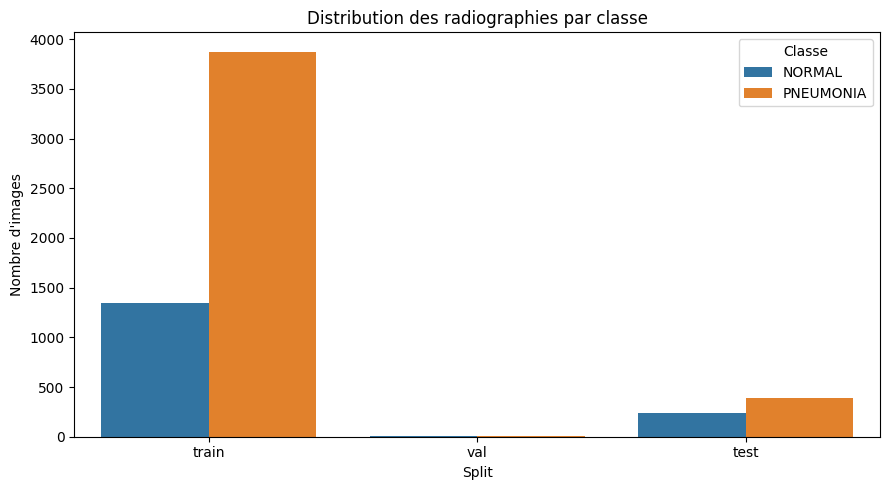

In [26]:

distribution = []

for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / "chest_xray" / split

    if split_dir.exists():
        for class_name in ["NORMAL", "PNEUMONIA"]:
            class_dir = split_dir / class_name

            distribution.append({
                "Split": split,
                "Classe": class_name,
                "Nombre": (
                    count_images(class_dir)
                    if class_dir.exists() else 0
                )
            })

df_distribution = pd.DataFrame(distribution)
display(df_distribution)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_distribution,
    x="Split",
    y="Nombre",
    hue="Classe"
)
plt.title("Distribution des radiographies par classe")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()

## 3. Dataset Loading and Preprocessing

In [56]:


#CNN dataset (Images 180x180)
train_ds_180 = image_dataset_from_directory(TRAIN_DIR, image_size=(180, 180), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary')
val_ds_180 = image_dataset_from_directory(VAL_DIR, image_size=(180, 180), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary')
test_ds_180 = image_dataset_from_directory(TEST_DIR, image_size=(180, 180), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary', shuffle=False)

#MobileNetV2 dataset (Images 224x224)
train_ds_224 = image_dataset_from_directory(TRAIN_DIR, image_size=(224, 224), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary')
val_ds_224 = image_dataset_from_directory(VAL_DIR, image_size=(224, 224), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary')
test_ds_224 = image_dataset_from_directory(TEST_DIR, image_size=(224, 224), batch_size=BATCH_SIZE, seed=SEED, label_mode='binary', shuffle=False)

normalization_layer = tf.keras.layers.Rescaling(1./255)
train_ds_180 = train_ds_180.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds_180 = val_ds_180.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds_180 = test_ds_180.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

mobile_preprocess = tf.keras.applications.mobilenet_v2.preprocess_input
train_ds_224 = train_ds_224.map(lambda x, y: (mobile_preprocess(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds_224 = val_ds_224.map(lambda x, y: (mobile_preprocess(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds_224 = test_ds_224.map(lambda x, y: (mobile_preprocess(x), y)).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


## 4. CNN model building and training

In [57]:
callbacks = [
    ModelCheckpoint(filepath=str(CHECKPOINT_PATH),monitor="val_auc",mode="max",save_best_only=True,verbose=1),
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6)
]
y_train = np.concatenate(
    [y.numpy() if hasattr(y, "numpy") else y for x, y in test_ds_180],
    axis=0
).reshape(-1)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

data_augmentation = Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

cnn_model = Sequential([
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(180, 180, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

cnn_model.compile(optimizer=optimizers.SGD(), loss='binary_crossentropy', metrics=[keras_metrics.Precision(),keras_metrics.Recall(),keras_metrics.F1Score(),keras_metrics.AUC()])
history_cnn = cnn_model.fit(train_ds_180, validation_data=val_ds_180, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/10


/venv/main/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


163/163 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - auc_10: 0.5316 - f1_score: 0.8456 - loss: 0.5882 - precision_10: 0.7318 - recall_10: 0.9730 - val_auc_10: 0.7891 - val_f1_score: 0.6667 - val_loss: 0.6382 - val_precision_10: 0.5714 - val_recall_10: 1.0000 - learning_rate: 0.0100
Epoch 2/10
  6/163 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - auc_10: 0.7666 - f1_score: 0.8174 - loss: 0.5443 - precision_10: 0.7435 - recall_10: 0.9592

/venv/main/lib/python3.10/site-packages/keras/src/callbacks/model_checkpoint.py:209: UserWarning: Can save best model only with val_auc available, skipping.
  self._save_model(epoch=epoch, batch=None, logs=logs)


163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_10: 0.7594 - f1_score: 0.8456 - loss: 0.4968 - precision_10: 0.7774 - recall_10: 0.9513 - val_auc_10: 0.8125 - val_f1_score: 0.6667 - val_loss: 0.6097 - val_precision_10: 0.5714 - val_recall_10: 1.0000 - learning_rate: 0.0100
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_10: 0.8724 - f1_score: 0.8456 - loss: 0.3889 - precision_10: 0.8472 - recall_10: 0.9296 - val_auc_10: 0.8594 - val_f1_score: 0.6667 - val_loss: 0.4870 - val_precision_10: 0.7778 - val_recall_10: 0.8750 - learning_rate: 0.0100
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_10: 0.9131 - f1_score: 0.8456 - loss: 0.3242 - precision_10: 0.8976 - recall_10: 0.9212 - val_auc_10: 0.8594 - val_f1_score: 0.6667 - val_loss: 0.4553 - val_precision_10: 0.7778 - val_recall_10: 0.8750 - learning_rate: 0.0100
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_10: 0.9495 - f1_score: 0.8456 - loss: 0.2524 - precision_10: 0.9309 - recall_10: 0.9332 - val_auc

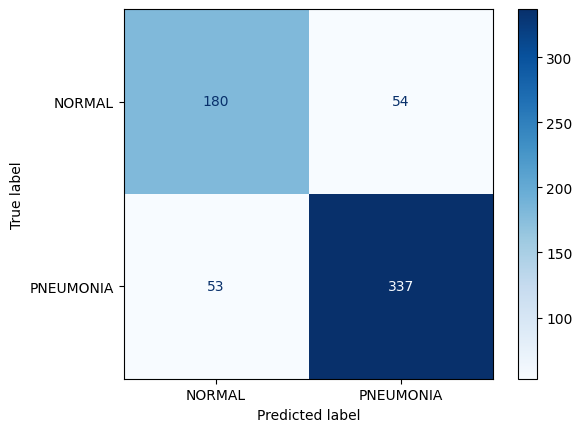

In [58]:
showConfusionMatrix(cnn_model,test_ds_180)

## 5. TRANSFER LEARNING WITH MOBILENETV2

In [59]:
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

mobilenet_model = Model(inputs, outputs)
mobilenet_model.compile(optimizer=optimizers.SGD(), loss=losses.BinaryCrossentropy(),metrics=[keras_metrics.Precision(),keras_metrics.Recall(),keras_metrics.F1Score(),keras_metrics.AUC()])

history_mb = mobilenet_model.fit(train_ds_224, validation_data=val_ds_224, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - auc_11: 0.8865 - f1_score: 0.8456 - loss: 0.3675 - precision_11: 0.8516 - recall_11: 0.9295 - val_auc_11: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.3166 - val_precision_11: 0.7273 - val_recall_11: 1.0000 - learning_rate: 0.0100
Epoch 2/10
  1/163 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - auc_11: 0.9714 - f1_score: 0.8571 - loss: 0.1931 - precision_11: 0.8519 - recall_11: 0.9583

/venv/main/lib/python3.10/site-packages/keras/src/callbacks/model_checkpoint.py:209: UserWarning: Can save best model only with val_auc available, skipping.
  self._save_model(epoch=epoch, batch=None, logs=logs)


163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_11: 0.9834 - f1_score: 0.8456 - loss: 0.1664 - precision_11: 0.9541 - recall_11: 0.9637 - val_auc_11: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.2941 - val_precision_11: 0.7273 - val_recall_11: 1.0000 - learning_rate: 0.0100
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_11: 0.9876 - f1_score: 0.8456 - loss: 0.1380 - precision_11: 0.9704 - recall_11: 0.9767 - val_auc_11: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.2807 - val_precision_11: 0.7273 - val_recall_11: 1.0000 - learning_rate: 0.0100
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_11: 0.9894 - f1_score: 0.8456 - loss: 0.1263 - precision_11: 0.9666 - recall_11: 0.9709 - val_auc_11: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.2707 - val_precision_11: 0.8000 - val_recall_11: 1.0000 - learning_rate: 0.0100
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - auc_11: 0.9910 - f1_score: 0.8456 - loss: 0.1152 - precision_11: 0.9749 - recall_11: 0.9723 - val_auc

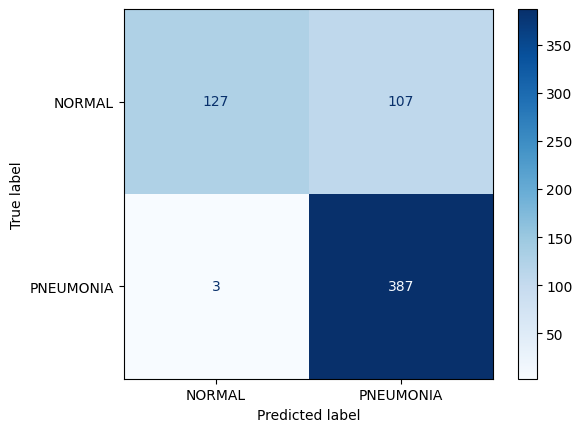

In [60]:
showConfusionMatrix(mobilenet_model,test_ds_224)

## 6. FINE-TUNING DE MOBILENETV2

In [61]:
base_model.trainable = True
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=optimizers.SGD(learning_rate=1e-5),
    loss=losses.BinaryCrossentropy(),
    metrics=[keras_metrics.Precision(),keras_metrics.Recall(),keras_metrics.F1Score(),keras_metrics.AUC()]
)

history_fine = mobilenet_model.fit(train_ds_224, validation_data=val_ds_224, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - auc_12: 0.8027 - f1_score: 0.8456 - loss: 0.4580 - precision_12: 0.8226 - recall_12: 0.9084 - val_auc_12: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.1638 - val_precision_12: 0.8889 - val_recall_12: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
  5/163 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc_12: 0.8065 - f1_score: 0.8186 - loss: 0.4849 - precision_12: 0.8139 - recall_12: 0.9028

/venv/main/lib/python3.10/site-packages/keras/src/callbacks/model_checkpoint.py:209: UserWarning: Can save best model only with val_auc available, skipping.
  self._save_model(epoch=epoch, batch=None, logs=logs)


163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc_12: 0.8220 - f1_score: 0.8456 - loss: 0.4406 - precision_12: 0.8280 - recall_12: 0.9317 - val_auc_12: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.1596 - val_precision_12: 0.8889 - val_recall_12: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc_12: 0.8339 - f1_score: 0.8456 - loss: 0.4308 - precision_12: 0.8340 - recall_12: 0.9248 - val_auc_12: 1.0000 - val_f1_score: 0.6667 - val_loss: 0.1763 - val_precision_12: 0.8889 - val_recall_12: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc_12: 0.8379 - f1_score: 0.8456 - loss: 0.4244 - precision_12: 0.8415 - recall_12: 0.9220 - val_auc_12: 0.9922 - val_f1_score: 0.6667 - val_loss: 0.2105 - val_precision_12: 0.8889 - val_recall_12: 1.0000 - learning_rate: 1.0000e-05
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc_12: 0.8622 - f1_score: 0.8456 - loss: 0.4021 - precision_12: 0.8389 - recall_12: 0.93

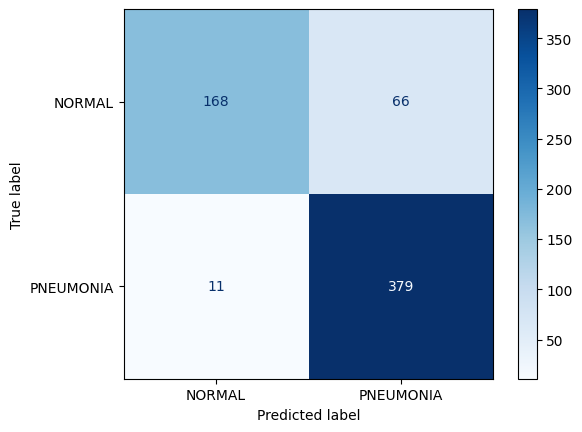

In [62]:
showConfusionMatrix(mobilenet_model,test_ds_224)

## 7. ÉVALUATION ET COMPARAISON

In [63]:
def evaluate_models(model, test_dataset, name):
    y_true = np.concatenate(
        [y.numpy() if hasattr(y, "numpy") else y
         for x, y in test_dataset],
        axis=0
    ).reshape(-1)

    y_pred_probs = model.predict(test_dataset, verbose=0).reshape(-1)

    y_pred = (y_pred_probs >= 0.5).astype(int)

    results = {
        "Model": name,
        "Accuracy": sklearn_metrics.accuracy_score(y_true, y_pred),
        "Precision": sklearn_metrics.precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": sklearn_metrics.recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": sklearn_metrics.f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": sklearn_metrics.roc_auc_score(
            y_true, y_pred_probs
        )
    }

    return results


results = []

results.append(
    evaluate_models(cnn_model, test_ds_180, "CNN Custom")
)

results.append(
    evaluate_models(
        mobilenet_model,
        test_ds_224,
        "MobileNetV2 Fine-Tuned"
    )
)

evaluation_df = pd.DataFrame(results)

print("\n===== MODEL EVALUATION COMPARISON =====")
print(evaluation_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


===== MODEL EVALUATION COMPARISON =====
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
            CNN Custom    0.8285     0.8619  0.8641    0.8630   0.9101
MobileNetV2 Fine-Tuned    0.8766     0.8517  0.9718    0.9078   0.9618


## 8. SAUVEGARDE DU MODÈLE RETENU ET FONCTION D'INFÉRENCE

In [64]:

mobilenet_model.save(FINAL_MODEL_PATH)
# files.download("/content/my_model.keras")
print(f"Modèle final sauvegardé sous : {FINAL_MODEL_PATH}")

Modèle final sauvegardé sous : /content/LungsLensAi/output/model_final.keras
